# Deo et al. 2024 — exploring the source data

Bimanual **cursor** iBCI. BrainGate2 participant **T5** (C4 spinal cord injury, tetraplegia;
two 96-channel Utah arrays = 192 channels in hand-knob motor cortex) controls two on-screen
cursors. On each trial one of three movement types is cued (unimanual right, unimanual left,
or bimanual) after a 1-2 s instructed delay. Source = Dryad `.mat`, read **locally in place**
(`scipy.io.loadmat`), one file per experiment day, each a whole-day concatenated stream with
many cued trials inside.

This notebook walks the raw layout: the 13 experiment days, the per-day fields, the 20 ms-binned
threshold crossings, the two cursors' and targets' trajectories, the trial timing / movement
types, and the open-loop vs closed-loop distinction.

> **Data path.** Source data lives on an external drive; this notebook reads its location from `NEURALSHED_DATA_ROOT`, loaded from a **gitignored `./.env`** at the repo root (via `load_dotenv`). Set it once there: `NEURALSHED_DATA_ROOT=/path/to/source/data`.


In [1]:
import warnings; warnings.filterwarnings("ignore")
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(usecwd=True))          # NEURALSHED_DATA_ROOT from the repo-root ./.env
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from neuralshed.datasets.deo_2024 import utils

print("data dir :", utils.DATA_DIR, "| exists:", utils.DATA_DIR.exists())
sessions = utils.list_sessions()
print(len(sessions), "sessions, participant", utils.SUBJECT, "|", utils.N_CHANNELS, "channels")


data dir : /media/heberto/Expansion/tether/datasets/deo_2024/data | exists: True
13 sessions, participant T5 | 192 channels


## 1. The 13 experiment days

One row per day: trial count, block count, the control loops present (open-loop / closed-loop /
closed-loop recalibration, from `utils.SESSION_BLOCKS`), and the per-movement-type trial counts.
Early days are open-loop only; later days add real-time closed-loop control.

In [2]:
rows = []
for s in sessions:
    tr = utils.get_trials(utils.session_path(s))
    counts = tr["move_type_name"].value_counts()
    rows.append(dict(
        session=s, date=utils.session_date(s), n_trials=len(tr),
        n_blocks=int(tr["block"].nunique()),
        loops=", ".join(sorted(tr["loop_type"].unique())),
        UniR=int(counts.get("UniR", 0)), UniL=int(counts.get("UniL", 0)),
        Bi=int(counts.get("Bi", 0)),
    ))
display(pd.DataFrame(rows))

,session,date,n_trials,n_blocks,loops,UniR,UniL,Bi
0,t5_06_02_2021,2021-06-02,1347,17,open_loop,307,342,698
1,t5_06_04_2021,2021-06-04,495,5,open_loop,111,121,263
2,t5_06_23_2021,2021-06-23,276,4,open_loop,65,67,144
3,t5_06_28_2021,2021-06-28,834,15,"closed_loop, closed_loop_recal, open_loop",286,274,274
4,t5_06_30_2021,2021-06-30,933,17,"closed_loop, closed_loop_recal, open_loop",295,315,323
5,t5_07_12_2021,2021-07-12,724,13,"closed_loop, closed_loop_recal, open_loop",243,241,240
6,t5_07_14_2021,2021-07-14,510,9,"closed_loop, open_loop",152,193,165
7,t5_09_13_2021,2021-09-13,762,18,"closed_loop, closed_loop_recal, open_loop",308,355,99
8,t5_09_15_2021,2021-09-15,972,25,"closed_loop, closed_loop_recal, open_loop",419,451,102
9,t5_09_27_2021,2021-09-27,1439,28,"closed_loop, open_loop",713,710,16


## 2. One day up close

Each `.mat` is one day: a `(192, T)` neural stream plus the two cursors' and targets' `(4, T)`
positions, keyed by a `(T,)` per-bin block index. We pick `t5_06_28_2021`, which has all three
control loops. `utils` returns neural time-first `(n_bins, 192)` and kinematics dims-first `(4, T)`.

In [3]:
sess = "t5_06_28_2021"                     # open-loop + closed-loop-recal + closed-loop
path = utils.session_path(sess)
tx = utils.get_threshold_crossings(path)   # (n_bins, 192)
cp = utils.get_cursor_positions(path)      # (4, n_bins)
tp = utils.get_target_positions(path)      # (4, n_bins)
trials = utils.get_trials(path)

n_bins = tx.shape[0]
print(f"{sess}: {n_bins} bins ({n_bins/utils.FS_NEURAL/60:.1f} min @ {utils.FS_NEURAL} Hz, "
      f"{utils.NEURAL_BIN_SIZE_MS} ms bins)")
print("threshold_crossings", tx.shape, tx.dtype)
print("cursor_position    ", cp.shape, "dims =", utils.CURSOR_DIMS)
print("target_position    ", tp.shape)
print(f"{len(trials)} trials across blocks {sorted(trials.block.unique())}")
display(trials.head())

t5_06_28_2021: 217498 bins (72.5 min @ 50 Hz, 20 ms bins)
threshold_crossings (217498, 192) uint8
cursor_position     (4, 217498) dims = ('right_x', 'right_y', 'left_x', 'left_y')
target_position     (4, 217498)
834 trials across blocks [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


,block,loop_type,move_type,move_type_name,go_cue_bin,delay_bins,move_bins,delay_start_bin,move_end_bin
0,5,open_loop,3,Bi,148,146,150,2,298
1,5,open_loop,2,UniL,423,122,157,301,580
2,5,open_loop,3,Bi,675,91,168,584,843
3,5,open_loop,3,Bi,932,85,153,847,1085
4,5,open_loop,1,UniR,1195,107,183,1088,1378


### Neural features for one trial

Threshold crossings over one open-loop bimanual trial's delay→move window (GO cue at `t = 0`).
No spike-band power is released for this dataset — threshold crossings are the only neural feature.

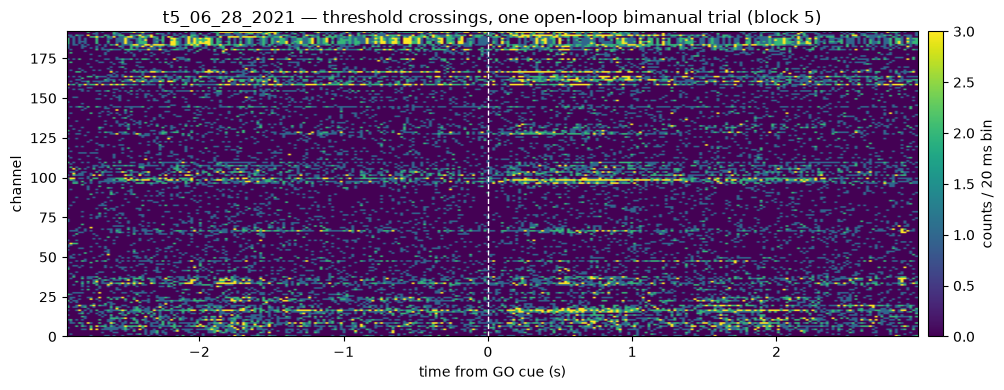

In [4]:
ol = trials[(trials.loop_type == "open_loop") & (trials.move_type_name == "Bi")].iloc[0]
a, b = int(ol.delay_start_bin), int(ol.move_end_bin)
seg = tx[a:b].T                            # (192 channels, bins)
t = (np.arange(seg.shape[1]) - (ol.go_cue_bin - a)) / utils.FS_NEURAL   # 0 at GO cue

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(seg, aspect="auto", origin="lower", cmap="viridis",
               vmin=0, vmax=np.percentile(seg, 98), extent=[t[0], t[-1], 0, utils.N_CHANNELS])
ax.axvline(0, color="w", ls="--", lw=1)    # GO cue
ax.set_xlabel("time from GO cue (s)"); ax.set_ylabel("channel")
ax.set_title(f"{sess} — threshold crossings, one open-loop bimanual trial (block {int(ol.block)})")
fig.colorbar(im, ax=ax, pad=0.01, label="counts / 20 ms bin")
plt.tight_layout(); plt.show()

## 3. Cursor & target trajectories

The behavioral signal is the two cursors' `(x, y)` positions (`right_x, right_y, left_x, left_y`).
For open-loop bimanual trials both cursors travel from center to their cued targets (`x` marks the
final target). This is the continuous kinematics the Phase-2 Study will emit as `PositionSeries`.

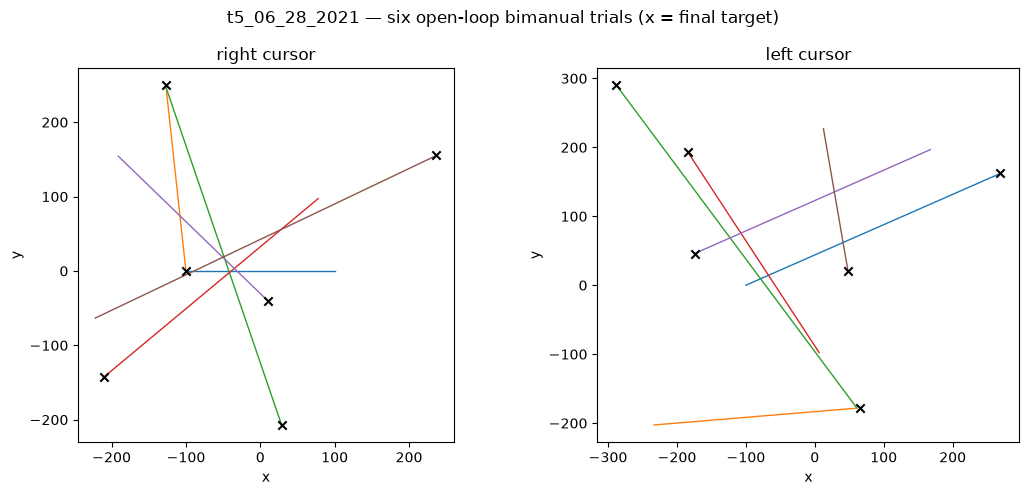

In [5]:
def trial_seg(arr, tr):                     # slice a (dims, n_bins) stream to a trial's delay->move window
    return arr[:, int(tr.delay_start_bin):int(tr.move_end_bin)]

ol_bi = trials[(trials.loop_type == "open_loop") & (trials.move_type_name == "Bi")].head(6)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for _, tr in ol_bi.iterrows():
    c, tgt = trial_seg(cp, tr), trial_seg(tp, tr)
    axes[0].plot(c[0], c[1], lw=1); axes[0].scatter(tgt[0, -1], tgt[1, -1], c="k", marker="x", zorder=3)
    axes[1].plot(c[2], c[3], lw=1); axes[1].scatter(tgt[2, -1], tgt[3, -1], c="k", marker="x", zorder=3)
for ax, name in zip(axes, ["right cursor", "left cursor"]):
    ax.set_title(name); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_aspect("equal")
fig.suptitle(f"{sess} — six open-loop bimanual trials (x = final target)")
plt.tight_layout(); plt.show()

## 4. Movement types & trial timing

`moveType` (per-trial, in the file) splits trials into unimanual-right, unimanual-left, and
bimanual. The instructed-delay structure is set by `durationBinnedDelay` (prep before GO) and
`durationBinnedMove` (movement after GO).

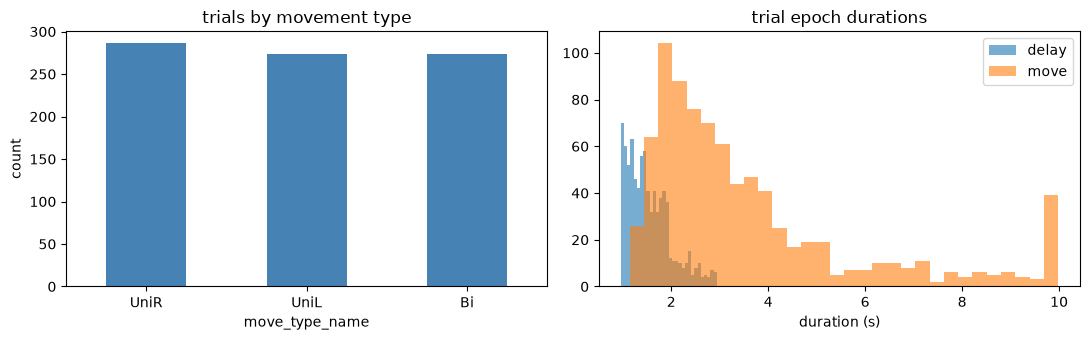

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
trials.move_type_name.value_counts().reindex(["UniR", "UniL", "Bi"]).plot.bar(
    ax=ax[0], color="steelblue")
ax[0].set_title("trials by movement type"); ax[0].set_ylabel("count")
ax[0].tick_params(axis="x", rotation=0)

ms = utils.NEURAL_BIN_SIZE_MS / 1000
ax[1].hist(trials.delay_bins * ms, bins=30, alpha=0.6, label="delay")
ax[1].hist(trials.move_bins * ms, bins=30, alpha=0.6, label="move")
ax[1].set_xlabel("duration (s)"); ax[1].set_title("trial epoch durations"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Open-loop vs closed-loop

The same `cursor_position` stream means different things across loop types: in **open-loop** blocks
the cursors follow an autonomous instructed trajectory to the target, while in **closed-loop** blocks
they are driven by a neural decoder (RNN or linear), so the paths are noisier and less direct. This
is a per-block property (`utils.SESSION_BLOCKS`) and a key attribute for Phase-2 filtering.

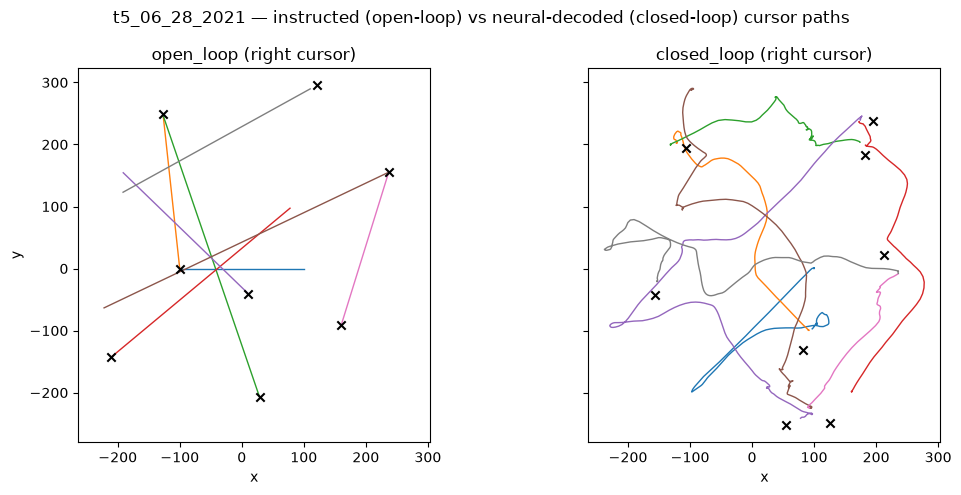

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, loop in zip(axes, ["open_loop", "closed_loop"]):
    sub = trials[(trials.loop_type == loop) & (trials.move_type_name == "Bi")].head(8)
    for _, tr in sub.iterrows():
        c, tgt = trial_seg(cp, tr), trial_seg(tp, tr)
        ax.plot(c[0], c[1], lw=1)                       # right cursor
        ax.scatter(tgt[0, -1], tgt[1, -1], c="k", marker="x", zorder=3)
    ax.set_title(f"{loop} (right cursor)"); ax.set_xlabel("x"); ax.set_aspect("equal")
axes[0].set_ylabel("y")
fig.suptitle(f"{sess} — instructed (open-loop) vs neural-decoded (closed-loop) cursor paths")
plt.tight_layout(); plt.show()

## Summary

- **Layout:** `data/t5_MM_DD_YYYY.mat`, one file per experiment day (13 days, ~135 MB); `utils`
  discovers and reads them.
- **Neural:** one 20 ms-binned (50 Hz) `threshold_crossings` stream (uint8), `(192, T)` in source /
  `(n_bins, 192)` from `utils`. No spike-band power in this release. Recording gaps at block changes.
- **Kinematics:** two cursors' and targets' `(x, y)` positions, `(4, T)` dims-first as
  `[right_x, right_y, left_x, left_y]`.
- **Trials:** `moveType` (UniR/UniL/Bi) is per-trial in the file; the instructed-delay window comes
  from `durationBinnedDelay` / `durationBinnedMove` around the 1-based `goCue`.
- **Loop type:** open-loop vs closed-loop (+ recalibration) is a per-block property from `readme.txt`
  (`utils.SESSION_BLOCKS`), and it changes what the cursor stream represents.

Next: `02_explore_study.ipynb` standardizes these into neuralset events.